# Are the "pseudo-genres" real structure? A k-means analysis of audio embeddings (RQ4)

## Background and question
This project studies the Yambda dataset (Yandex Music listening logs) and asks whether recommendations broaden or narrow what people listen to.
Yambda is fully anonymous: tracks have no titles and **no genre labels**. The only information about what a track *sounds like* is a
**128-dimensional audio embedding** per track (a vector produced by a neural network from the audio).
To talk about "genres" we therefore build **pseudo-genres**: we cluster the embeddings with k-means and call each cluster a pseudo-genre.
These pseudo-genres are later used to measure how many different genres a user's listening spans.

That measurement is only as good as the clustering. **Research question 4:** are the pseudo-genres *real structure in the sound space*, or an
*artefact of k-means*? (k-means always returns exactly k clusters, even on random data, and k is a number we pick.)
This notebook is the **k-means half** of that question: it selects k with standard criteria and tests whether the clusters contain structure beyond what k-means finds in noise.
A separate analysis approaches the same question with graph communities (Louvain) built from co-listening; the two will be compared using the label file written at the end of this notebook.

## Plan: what each step is for
| # | Step | What we want to learn |
|---|---|---|
| 1 | Data and method | what is clustered, which k-means variant and why, and a check that our implementation is correct |
| 2 | Elbow (inertia) | does the within-cluster tightness reveal a natural number of clusters? |
| 3 | Silhouette | how clearly are clusters separated from each other, at each k? |
| 4 | Null model | would k-means give the same numbers on data with no structure? (the reference that makes sections 2 and 3 interpretable) |
| 5 | Stability | does a different random start give the same clusters? |
| 6 | External check | do the clusters agree with something k-means never saw (artist identity)? |
| 7 | Decision | combine all criteria, choose k, describe the chosen clusters, export the labels |
| 8 | Summary | answer to the question, and limitations |

*Prerequisites:* the processed embeddings in `data/processed/emb50m_*.npy` (created by `scripts/extract_embeddings_50m.py`) and the artist mapping in `data/raw/yambda/`.
Run time: roughly 10 minutes (about 4 min for the real data, 3 min for the null model, the rest for silhouettes and checks). Memory: below 3 GB.

## 0. Setup and parameters

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# ---------------- parameters (change here, then Run All) ----------------
K_GRID = [2, 4, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192]   # candidate numbers of clusters
N_FIT = 150_000        # tracks used to fit k-means (random sample of the 848k embedded tracks)
N_SEEDS = 5            # independent k-means runs (different k-means++ seeds) per k
N_SIL = 10_000         # tracks for the exact (pairwise) silhouette
K_CHOSEN = 32          # final k, set in section 7 after reading sections 2-6
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC = "#264653", "#9aa0a6", "#e76f51"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA, PROC, OUT = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed", ROOT / "RQ4_kmeans"
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Data and method

### 1.1 What is clustered, and why it is prepared this way
**Data.** One 128-dimensional audio embedding for each of 848k tracks (the tracks that occur in the Yambda-50M sample of listening events).

**Normalisation to unit length (L2).** We care about the *direction* of an embedding (what kind of sound it encodes), not its length. After normalising, cosine similarity equals a plain dot product,
and Euclidean distance becomes a monotone function of cosine similarity. This lets us use k-means machinery while still measuring similarity by angle, the natural choice for embeddings.

**Why only a random sample of 150,000 tracks is used to fit.** We fit 12 values of k with 5 random starts each; fitting on all 848k tracks would multiply the run time for little gain, because each cluster
is still estimated from thousands of tracks. Afterwards every one of the 848k tracks is assigned to its nearest centroid, so nothing is left out of the final labels.
The exact silhouette (section 3) compares every point with every other point, which grows with the square of the number of points, so it uses a smaller sample of 10,000 tracks.

**First look: principal components.** Before clustering, we ask how many directions carry the variance. If two or three components explained almost everything, the space would be nearly low-dimensional;
if the variance is spread over dozens of directions, any structure is high-dimensional and subtle, and we should not expect clean, visually obvious groups.

847,921 embedded tracks; fitting on a random sample of 150,000  (0 s)


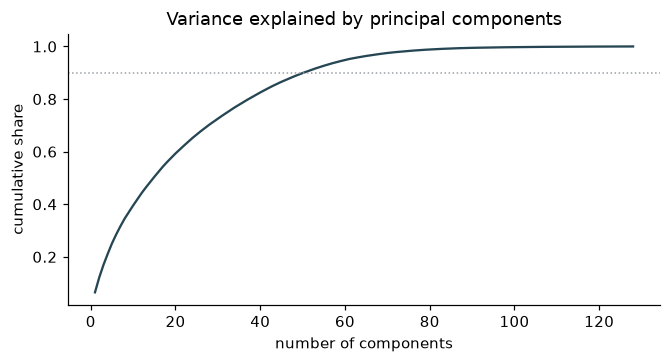

components for 50% / 80% / 90% of the variance: 15 / 38 / 51  (of 128)


In [2]:
t0 = time.time()
emb_ids = np.load(PROC / "emb50m_item_ids.npy")
EN = np.load(PROC / "emb50m_norm.npy")                       # (848k, 128) float32, unit length
assert np.allclose(np.linalg.norm(EN[:1000], axis=1), 1, atol=1e-4)
fit_idx = rng.choice(len(EN), N_FIT, replace=False)
X = EN[fit_idx]
sil_idx = rng.choice(N_FIT, N_SIL, replace=False)
print(f"{len(EN):,} embedded tracks; fitting on a random sample of {len(X):,}  ({time.time() - t0:.0f} s)")

# how much linear structure is there? share of variance in the leading principal components
pca = PCA(n_components=128, random_state=SEED).fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(np.arange(1, 129), cum, color=REAL); ax.axhline(0.9, color=NULL, ls=":", lw=1)
ax.set(title="Variance explained by principal components", xlabel="number of components", ylabel="cumulative share")
plt.tight_layout(); plt.show()
print(f"components for 50% / 80% / 90% of the variance: "
      f"{int(np.searchsorted(cum, .5)) + 1} / {int(np.searchsorted(cum, .8)) + 1} / {int(np.searchsorted(cum, .9)) + 1}  (of 128)")

### 1.2 Method: spherical k-means, and why this variant
**Why k-means.** We need a *partition* of tracks into a modest number of groups, each with a centroid that can be interpreted and reused to assign new tracks. k-means does this, scales to hundreds of thousands of points,
and is one of the course methods we implement ourselves. Alternatives (hierarchical clustering, Gaussian mixtures, density-based methods) are much heavier on this many points or need extra assumptions; we list them as a limitation.

**Why the spherical (cosine) variant.** Embeddings are compared by angle. Each track is assigned to the centroid with the **highest cosine similarity**, and each centroid is the **re-normalised mean** of its members, so a centroid is itself a direction.

**Why k-means++ seeding.** Choosing the initial centres at random can put several of them in the same dense region and lock the algorithm into a poor solution. k-means++ picks each new centre with probability proportional to its squared distance from the centres already chosen, which spreads them out.
We stop when fewer than 0.05% of the assignments change, or after 60 iterations. An empty cluster is re-seeded with a random track.

**Why our own implementation.** Writing the algorithm ourselves is part of the course work. Because home-made code can hide mistakes, section 7.3 checks it against scikit-learn's `KMeans`.

**Quantities used throughout** (all on unit vectors; $c_j$ is the unit centroid of cluster $j$ and $x_i$ belongs to cluster $j(i)$):

- *Inertia* $=\sum_i (1-\cos(x_i, c_{j(i)}))$: the total cosine distance to the own centroid, a measure of tightness. Lower is tighter. It always falls as k grows, so it cannot choose k by itself; that is why we look for an elbow.
- *Silhouette* $s_i=\frac{b_i-a_i}{\max(a_i,b_i)}$, where $a_i$ is the mean cosine distance to the other members of the own cluster and $b_i$ the same to the nearest other cluster. It ranges from $-1$ to $1$ and measures *separation* as well as tightness; near 0 means the point sits on a boundary. We compute the **exact** version on 10,000 tracks and a **centroid-based "simplified" version** (distances to centroids instead of to all members) on all 150,000 fitted tracks as a cheaper cross-check.
- *Adjusted Rand index (ARI):* agreement between two partitions of the same items, corrected for chance and independent of how the clusters are numbered. 0 means chance level, 1 means identical.

In [3]:
def spherical_kmeans(X, k, seed, n_iter=60):
    r = np.random.default_rng(seed); n = len(X)
    C = np.empty((k, X.shape[1]), dtype=np.float32); C[0] = X[r.integers(n)]
    dist = 1 - X @ C[0]
    for j in range(1, k):                                   # k-means++ seeding with cosine distance
        pr = np.maximum(dist, 0) ** 2; C[j] = X[r.choice(n, p=pr / pr.sum())]
        dist = np.minimum(dist, 1 - X @ C[j])
    labels = np.full(n, -1)
    for _ in range(n_iter):
        new = np.argmax(X @ C.T, axis=1)
        if (new == labels).mean() > 0.9995:
            labels = new; break
        labels = new
        sums = csr_matrix((np.ones(n, np.float32), (labels, np.arange(n))), shape=(k, n)) @ X
        nrm = np.linalg.norm(sums, axis=1, keepdims=True)
        empty = nrm[:, 0] == 0
        sums[empty] = X[r.integers(n, size=empty.sum())]; nrm[empty] = 1
        C = (sums / np.maximum(nrm, 1e-9)).astype(np.float32)
    return C, labels, float((X * C[labels]).sum(1).mean())   # centroids, labels, mean cosine to own centroid


def simplified_silhouette(X, C, labels):
    # centroid-based silhouette per point: a = 1 - cos(own centroid), b = 1 - cos(nearest other centroid)
    S = X @ C.T
    own = S[np.arange(len(X)), labels]
    S[np.arange(len(X)), labels] = -np.inf
    a, b = 1 - own, 1 - S.max(axis=1)
    return (b - a) / np.maximum(np.maximum(a, b), 1e-9)


def run_sweep(Xs, k_grid, n_seeds, tag):
    rows, store = [], {}
    sidx = rng.choice(len(Xs), N_SIL, replace=False)
    for k in k_grid:
        for s in range(n_seeds):
            t1 = time.time()
            C_, lab_, obj = spherical_kmeans(Xs, k, SEED + 100 * s)
            sizes = np.bincount(lab_, minlength=k) / len(lab_)
            rows.append(dict(data=tag, k=k, seed=s, mean_cos=obj, inertia=len(Xs) * (1 - obj),
                             sil_exact=silhouette_score(Xs[sidx], lab_[sidx], metric="cosine"),
                             sil_simpl=simplified_silhouette(Xs, C_, lab_).mean(),
                             min_share=sizes.min(), max_share=sizes.max(),
                             size_entropy=-(sizes[sizes > 0] * np.log(sizes[sizes > 0])).sum() / np.log(k),
                             seconds=time.time() - t1))
            store[(k, s)] = (C_, lab_)
        print(f"[{tag}] k={k:>3} done", end="  ")
    print()
    return pd.DataFrame(rows), store

### 1.3 Fit the full grid on the real embeddings
**What we do.** We fit k-means for 12 values of k, spaced roughly geometrically from 2 to 192 (the interesting differences are ratios, not absolute steps), each with 5 independent random starts.

**What we want to learn.** The values of inertia, silhouette and cluster sizes at every k, and, from the spread across the 5 starts, how much each number depends on luck of the initialisation. All fitted clusterings are kept for the stability analysis in section 5.

In [4]:
t0 = time.time()
res_real, store_real = run_sweep(X, K_GRID, N_SEEDS, "real")
print(f"{time.time() - t0:.0f} s in total")

[real] k=  2 done  

[real] k=  4 done  

[real] k=  8 done  

[real] k= 12 done  

[real] k= 16 done  

[real] k= 24 done  

... (2 outputs left out)

[real] k= 64 done  

[real] k= 96 done  

[real] k=128 done  

[real] k=192 done  
255 s in total


## 2. Elbow method: where do extra clusters stop paying off?

**Why.** We cannot simply minimise inertia: it decreases with every extra cluster and reaches zero when every track is its own cluster. What matters is *where the improvement slows down*.
If the data had a natural number of groups, inertia would fall steeply until that number and slowly afterwards, a bend or "elbow" in the curve.

**What we do.** We plot inertia (equivalently the mean cosine of a track to its centroid) against k. Reading a bend by eye is subjective, so we add two aids:

- the **relative inertia reduction per doubling of k**: for a curve without a natural scale this stays flat, and if there is a natural number of groups it drops after it;
- an automatic **knee** (the Kneedle idea: the point farthest below the straight line between the first and last points of the normalised curve), computed on k and on log₂ k because the answer can depend on the axis.

**What we want to learn.** Is there a k beyond which extra clusters buy little tightness, or is the curve smooth, which would mean that no k is singled out by tightness alone?

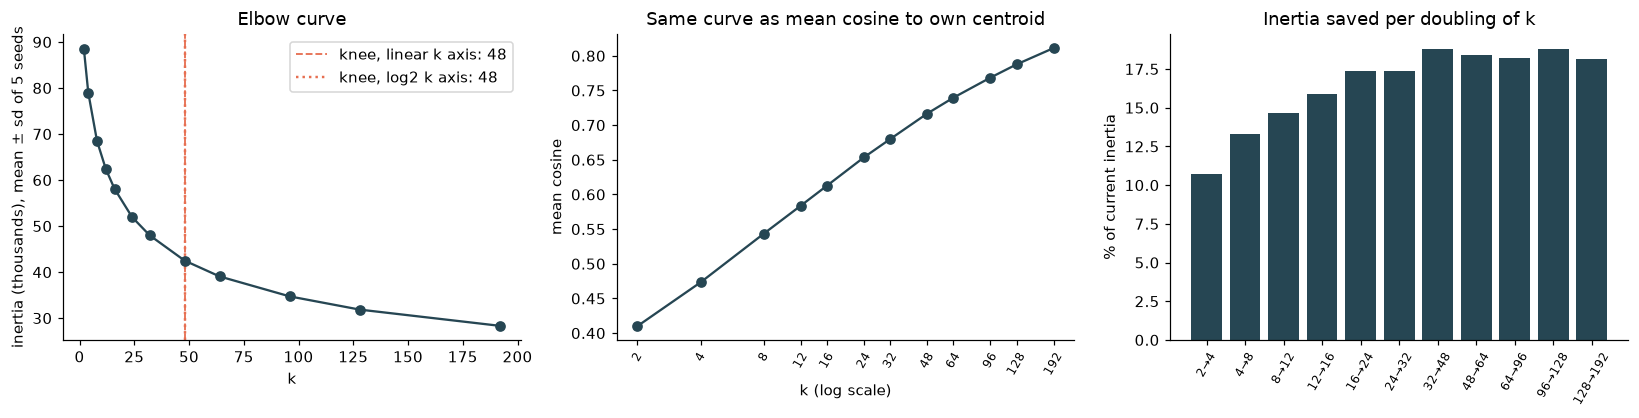

  k  inertia (mean)  sd across seeds  mean cosine
  2     88,476.5616         199.4510       0.4102
  4     78,998.8562         113.4193       0.4733
  8     68,470.4894         275.0051       0.5435
 12     62,420.1214         375.8267       0.5839
 16     58,087.6297         351.5337       0.6127
 24     51,960.9654         306.3220       0.6536
 32     48,007.8971         266.0189       0.6799
 48     42,499.1888          62.8783       0.7167
 64     39,058.1667          87.7317       0.7396
 96     34,724.5610          63.2305       0.7685
128     31,852.0296          60.4180       0.7877
192     28,327.0365          47.2885       0.8112
saved per doubling (%): [10.71 13.33 14.63 15.91 17.35 17.36 18.81 18.41 18.21 18.78 18.17]


In [5]:
g = res_real.groupby("k")
inertia_m, inertia_s = g["inertia"].mean(), g["inertia"].std()
ks = np.array(K_GRID)

def knee(x, y):
    xn = (x - x.min()) / (x.max() - x.min()); yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax((1 - xn) - yn))            # distance below the chord of a decreasing convex curve

knee_lin, knee_log = ks[knee(ks.astype(float), inertia_m.values)], ks[knee(np.log2(ks), inertia_m.values)]
per_doubling = 1 - (inertia_m.values[1:] / inertia_m.values[:-1]) ** (1 / np.log2(ks[1:] / ks[:-1]))

def logk(a_):
    a_.set_xscale("log"); a_.set_xticks(ks); a_.set_xticklabels(ks, rotation=60, fontsize=8); a_.minorticks_off()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
ax[0].errorbar(ks, inertia_m / 1e3, yerr=inertia_s / 1e3, fmt="o-", color=REAL, capsize=2)
ax[0].axvline(knee_lin, color=ACC, ls="--", lw=1.2, label=f"knee, linear k axis: {knee_lin}")
ax[0].axvline(knee_log, color=ACC, ls=":", lw=1.6, label=f"knee, log2 k axis: {knee_log}")
ax[0].set(title="Elbow curve", xlabel="k", ylabel="inertia (thousands), mean ± sd of 5 seeds"); ax[0].legend()
ax[1].plot(ks, g["mean_cos"].mean(), "o-", color=REAL)
ax[1].set(title="Same curve as mean cosine to own centroid", xlabel="k (log scale)", ylabel="mean cosine"); logk(ax[1])
ax[2].bar(range(1, len(ks)), per_doubling * 100, color=REAL)
ax[2].set_xticks(range(1, len(ks))); ax[2].set_xticklabels([f"{a}→{b}" for a, b in zip(ks[:-1], ks[1:])], rotation=60, fontsize=8)
ax[2].set(title="Inertia saved per doubling of k", ylabel="% of current inertia")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": ks, "inertia (mean)": inertia_m.values, "sd across seeds": inertia_s.values,
                    "mean cosine": g["mean_cos"].mean().values}).to_string(index=False, float_format=lambda x: f"{x:,.4f}"))
print("saved per doubling (%):", np.round(per_doubling * 100, 2))

### 2.1 Reading the elbow

**There is no elbow.** Inertia falls smoothly from 88.5k (k = 2) to 28.3k (k = 192). If there were a natural number of clusters, the saving
per doubling of k would shrink after it. Instead it *rises* from 10.7% (2→4) to about 18% from k = 32 on and then stays flat: every doubling removes roughly the same fraction of the remaining
inertia. That is the signature of data without a natural cluster scale, a continuum that can be cut finer and finer.

The automatic knee detector returns k = 48 on both axes, but on a curve this smooth that is only the point farthest from the chord, a
product of the chosen grid range, not a bend. We do not treat it as evidence. Seed noise (sd 0.05k to 0.4k) is tiny next to the differences between
k values, so the curve is reliable; it simply does not contain an answer. **The elbow alone does not select k.**

## 3. Silhouette: how well separated are the clusters?

**Why.** The elbow looks only at tightness *within* clusters. A good clustering should also have clusters that are *far from each other*. The silhouette combines both: for each track it compares the distance to its own cluster with the distance to the nearest other cluster.
Unlike inertia it is not forced to improve with every k, so it can have a maximum and can act as a selection rule.

**What we do.** We compute the exact silhouette on 10,000 tracks (all pairwise cosine distances; a sample is needed because the cost grows with the square of the sample size), and the centroid-based version on all 150,000 tracks.
If both have the same shape across k, the cheap version is a trustworthy guide. We also plot every individual run, to separate real trends from seed noise.

**What we want to learn.** Which k (if any) gives the best-separated clusters, and, from the absolute level, whether the clusters are distinct groups (values near 1) or neighbouring regions of a continuum (values near 0).

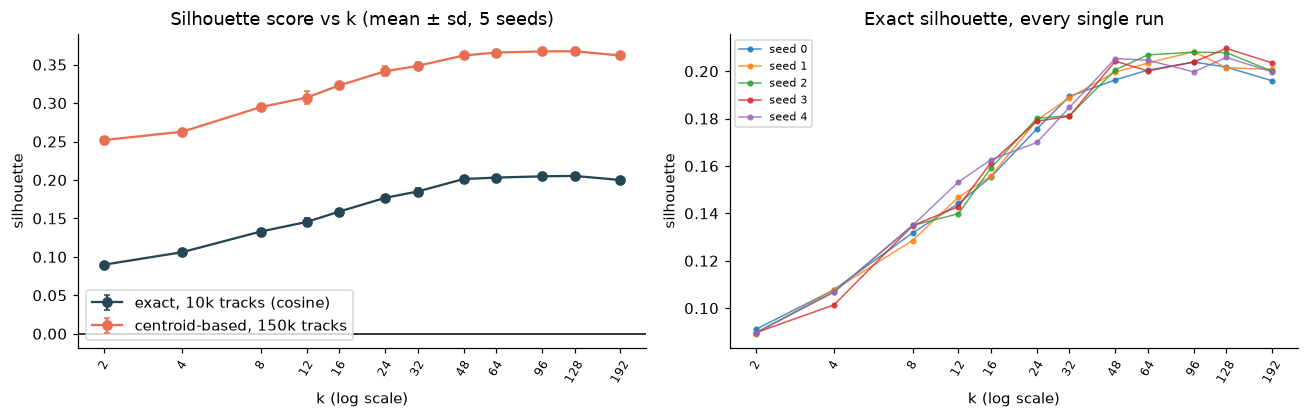

    sil_exact        sil_simpl       
         mean    std      mean    std
k                                    
2      0.0898 0.0007    0.2519 0.0035
4      0.1061 0.0027    0.2628 0.0038
8      0.1330 0.0028    0.2948 0.0025
12     0.1454 0.0051    0.3071 0.0082
16     0.1589 0.0033    0.3230 0.0036
24     0.1768 0.0042    0.3413 0.0064
32     0.1850 0.0040    0.3484 0.0047
48     0.2012 0.0036    0.3619 0.0023
64     0.2031 0.0029    0.3657 0.0017
96     0.2047 0.0035    0.3672 0.0025
128    0.2053 0.0036    0.3674 0.0036
192    0.2000 0.0027    0.3619 0.0025

k with the highest mean exact silhouette: 128 | highest simplified: 128


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for col, lab, c in [("sil_exact", "exact, 10k tracks (cosine)", REAL), ("sil_simpl", "centroid-based, 150k tracks", ACC)]:
    m, s = g[col].mean(), g[col].std()
    ax[0].errorbar(ks, m, yerr=s, fmt="o-", color=c, capsize=2, label=lab)
ax[0].axhline(0, color="k", lw=1); logk(ax[0])
ax[0].set(title="Silhouette score vs k (mean ± sd, 5 seeds)", xlabel="k (log scale)", ylabel="silhouette"); ax[0].legend()
for s in range(N_SEEDS):
    d = res_real[res_real.seed == s]; ax[1].plot(d["k"], d["sil_exact"], "o-", lw=1, ms=3, alpha=.8, label=f"seed {s}")
logk(ax[1]); ax[1].set(title="Exact silhouette, every single run", xlabel="k (log scale)", ylabel="silhouette"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(g[["sil_exact", "sil_simpl"]].agg(["mean", "std"]).to_string(float_format=lambda x: f"{x:.4f}"))
print("\nk with the highest mean exact silhouette:", int(g["sil_exact"].mean().idxmax()),
      "| highest simplified:", int(g["sil_simpl"].mean().idxmax()))

### 3.1 Reading the silhouette

Silhouette rises from 0.09 (k = 2) to 0.185 at k = 32 and then **levels off at about 0.20 from k = 48** (0.201 at 48, 0.203 at 64, 0.205 at 96 and 128, 0.200 at 192).
The formal maximum is at k = 96 to 128, but the differences between k = 48 and 128 (at most 0.004) are the size of the seed-to-seed sd (0.003 to 0.004),
so there is no meaningful maximum, only a plateau starting around 48.

Two cautions about the *level*:
- A common rule of thumb (Kaufman and Rousseeuw) reads silhouette below about 0.25 as "no substantial structure". All our values (0.09 to 0.21) are in that range: the clusters are **weakly separated**. Section 4 shows that this is still far from noise.
- The centroid-based version is higher (0.25 to 0.37) because distances to a centroid are shorter than average distances to all members, so the two absolute levels are not comparable. Their *shape* is identical (both peak at k = 128), so the cheap version is a faithful guide to the shape.

Silhouette alone says "k of at least 48"; it never penalises additional clusters in this range.

## 4. Null model: would k-means look the same on structureless data?

**Why.** This is the core of "real structure or artefact". k-means returns k clusters on *any* data, and inertia and silhouette have values on any data, so an absolute number
(for example "silhouette 0.2") means nothing without a reference. We need to know what k-means reports when there is *no* structure to find.

**What we do.** We build a **null dataset**: each of the 128 embedding columns is shuffled independently across tracks, then every row is re-normalised to unit length.
This keeps the distribution of every single dimension, the number of tracks and the unit-length constraint, but destroys all dependence *between* dimensions, i.e. any structure that makes some tracks sound alike.
(We chose this over, for instance, uniformly random points on the sphere because it keeps the same per-dimension statistics, so any difference to the real data can only come from dependence between dimensions.)
We run the same k grid on it with 3 starts per k (the null values hardly vary, so fewer starts suffice).

**What we want to learn.** The *gap* between real and null at the same k is the structure beyond what k-means finds by itself. If the real curves lie clearly above the null, the clusters are not an artefact of the algorithm.

[null (columns shuffled)] k=  2 done  

[null (columns shuffled)] k=  4 done  

[null (columns shuffled)] k=  8 done  

[null (columns shuffled)] k= 12 done  

[null (columns shuffled)] k= 16 done  

[null (columns shuffled)] k= 24 done  

... (2 outputs left out)

[null (columns shuffled)] k= 64 done  

[null (columns shuffled)] k= 96 done  

[null (columns shuffled)] k=128 done  

[null (columns shuffled)] k=192 done  
155 s


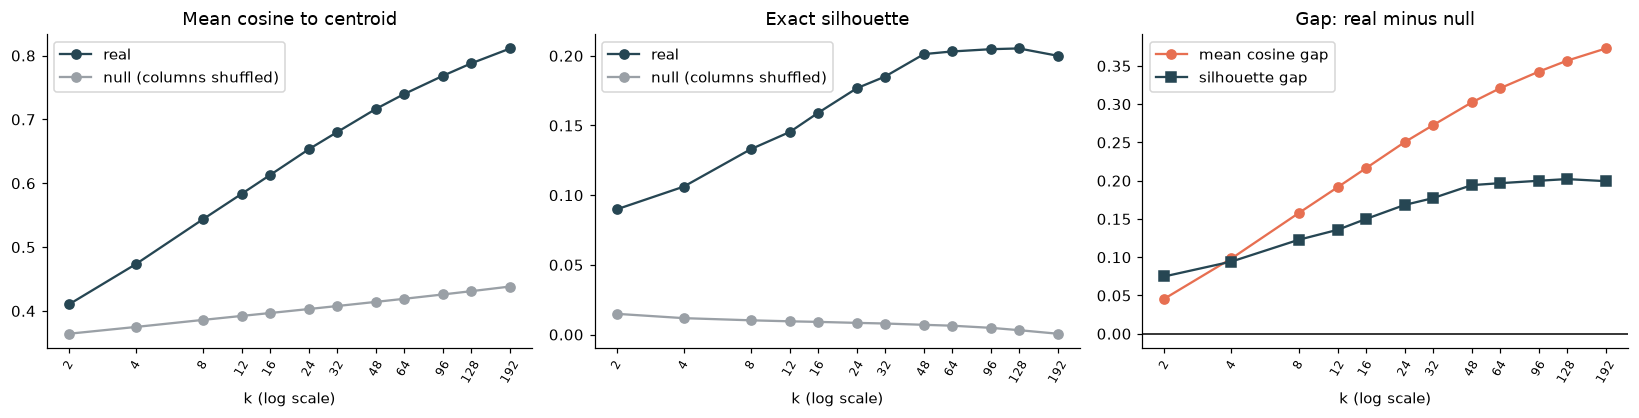

  k  cos real  cos null  sil real  sil null
  2    0.4102    0.3643    0.0898    0.0149
  4    0.4733    0.3750    0.1061    0.0118
  8    0.5435    0.3860    0.1330    0.0102
 12    0.5839    0.3923    0.1454    0.0095
 16    0.6127    0.3968    0.1589    0.0091
 24    0.6536    0.4031    0.1768    0.0084
 32    0.6799    0.4077    0.1850    0.0079
 48    0.7167    0.4143    0.2012    0.0070
 64    0.7396    0.4190    0.2031    0.0064
 96    0.7685    0.4259    0.2047    0.0048
128    0.7877    0.4310    0.2053    0.0032
192    0.8112    0.4383    0.2000    0.0006


In [7]:
Xnull = X.copy()
for j in range(Xnull.shape[1]):
    Xnull[:, j] = Xnull[rng.permutation(len(Xnull)), j]
Xnull /= np.linalg.norm(Xnull, axis=1, keepdims=True)
t0 = time.time()
res_null, _ = run_sweep(Xnull, K_GRID, 3, "null (columns shuffled)")
print(f"{time.time() - t0:.0f} s")
both = pd.concat([res_real, res_null])
gb = both.groupby(["data", "k"])[["mean_cos", "sil_exact", "sil_simpl"]].mean().reset_index()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for name, c in [("real", REAL), ("null (columns shuffled)", NULL)]:
    d = gb[gb.data == name]
    ax[0].plot(d["k"], d["mean_cos"], "o-", color=c, label=name); ax[1].plot(d["k"], d["sil_exact"], "o-", color=c, label=name)
ra, nu = gb[gb.data == "real"].set_index("k"), gb[gb.data != "real"].set_index("k")
ax[2].plot(ks, (ra["mean_cos"] - nu["mean_cos"]).values, "o-", color=ACC, label="mean cosine gap")
ax[2].plot(ks, (ra["sil_exact"] - nu["sil_exact"]).values, "s-", color=REAL, label="silhouette gap")
for a_, t in zip(ax, ["Mean cosine to centroid", "Exact silhouette", "Gap: real minus null"]):
    logk(a_); a_.set(title=t, xlabel="k (log scale)"); a_.legend()
ax[2].axhline(0, color="k", lw=1)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": ks, "cos real": ra["mean_cos"].values, "cos null": nu["mean_cos"].values,
                    "sil real": ra["sil_exact"].values, "sil null": nu["sil_exact"].values}).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

### 4.1 Reading the null comparison

On the shuffled data k-means behaves as it should on structureless data: silhouette is about 0 (0.015 at k = 2, falling to 0.001 at k = 192), against 0.09 to 0.21 on the real
embeddings. The mean cosine to the own centroid is 0.36 to 0.44 on the null and 0.41 to 0.81 on the real data, and the gap grows with k (0.05 at k = 2, 0.27 at k = 32, 0.37 at k = 192).

So **the clusters are not what k-means produces on noise**: the embedding dimensions depend on each other, and the clustering exploits this.

What this does *not* show: the null removes all joint structure, which is a lenient bar. It proves "not noise", not "separate islands". A smooth, curved continuum would also beat
this null. Together with the low absolute silhouette (section 3), the picture is **real but graded structure**, not sharply separated genres.

## 5. Stability: does the same k give the same clusters?

**Why.** k-means depends on its random start. If the clusters reflect real structure, different starts should find (nearly) the same groups. If they do not, the boundaries between clusters are partly arbitrary.

**What we do.** For every k we compute the **adjusted Rand index between all 10 pairs of the 5 runs**. We use ARI because it is corrected for chance and does not depend on how the clusters are numbered (cluster 3 in one run may be cluster 17 in another).

**What we want to learn.** How reproducible the partition is at each k. Note that stability is not the same as truth (a smooth continuum can be cut into stable slices), but instability is a clear warning.
It also gives a practical yardstick: two different methods cannot be expected to agree with each other more than k-means agrees with itself.

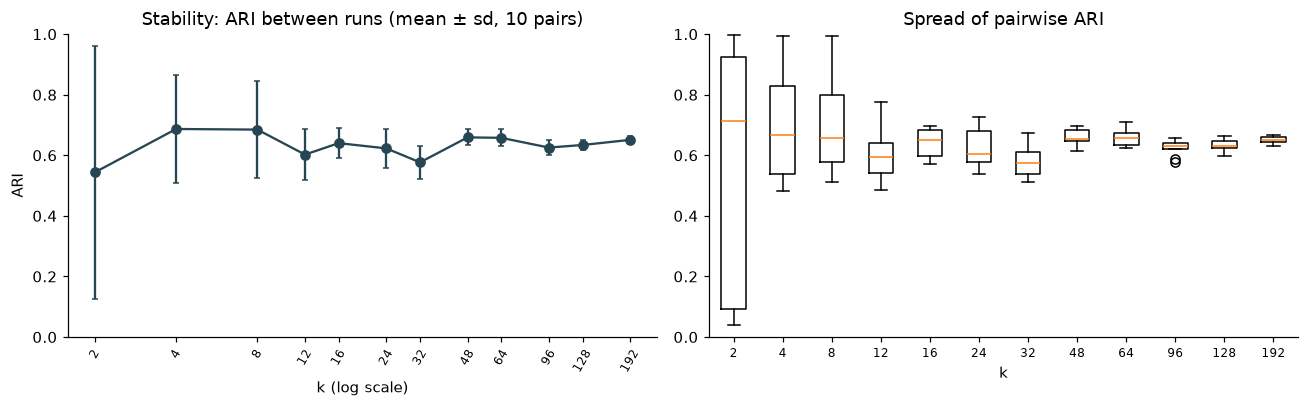

     mean   min   max
k                    
2   0.544 0.041 0.998
4   0.687 0.482 0.994
8   0.685 0.511 0.995
12  0.602 0.486 0.778
16  0.640 0.571 0.697
24  0.623 0.538 0.727
32  0.577 0.511 0.675
48  0.659 0.613 0.696
64  0.658 0.623 0.709
96  0.626 0.579 0.658
128 0.634 0.599 0.664
192 0.651 0.630 0.668


In [8]:
from itertools import combinations
rows = []
for k in K_GRID:
    for a, b in combinations(range(N_SEEDS), 2):
        rows.append(dict(k=k, ari=adjusted_rand_score(store_real[(k, a)][1], store_real[(k, b)][1])))
stab = pd.DataFrame(rows); sg = stab.groupby("k")["ari"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].errorbar(ks, sg.mean(), yerr=sg.std(), fmt="o-", color=REAL, capsize=2)
logk(ax[0]); ax[0].set(title="Stability: ARI between runs (mean ± sd, 10 pairs)", xlabel="k (log scale)", ylabel="ARI", ylim=(0, 1))
ax[1].boxplot([stab[stab.k == k]["ari"] for k in K_GRID], tick_labels=K_GRID); ax[1].set(title="Spread of pairwise ARI", xlabel="k", ylim=(0, 1))
plt.setp(ax[1].get_xticklabels(), fontsize=8)
plt.tight_layout(); plt.show()
print(sg.agg(["mean", "min", "max"]).to_string(float_format=lambda x: f"{x:.3f}"))

### 5.1 Reading the stability

Different seeds agree only **partially**: the mean pairwise ARI is 0.58 to 0.69 for every k of at least 4, and never close to 1. At k = 2 the mean is 0.54 with pairs ranging from 0.04 to 0.998, i.e. two competing
two-way splits. k = 4 and 8 reach 0.69, k = 32 is the lowest of the grid (0.58), and k = 48 and above sit at 0.63 to 0.66. The differences between neighbouring k are about as large as the spread across pairs (boxplot),
so stability does not single out any k.

Interpretation: the broad regions of the sound space are found consistently, but where the boundaries fall is partly arbitrary, which is what one expects from a continuum.
Our k-means against scikit-learn at k = 32 gives ARI 0.71 (section 7.3), *higher* than between our own seeds (0.58), so differences between implementations are smaller than differences between seeds.

Consequence: individual track-to-cluster assignments are not reproducible across seeds, and conclusions should be drawn on cluster-level aggregates (for example the share of a user's listening that falls in each pseudo-genre),
not on single tracks. It also bounds any comparison with Louvain: two methods cannot be expected to agree more (in ARI) than k-means agrees with itself.

## 6. Meaning: do clusters line up with artists?

**Why.** Sections 2 to 5 judge the clustering by properties of the clustering itself. A stronger test uses information **k-means never saw**. The dataset has no genres, but it does record which artist made each track.
If pseudo-genres capture something about music, tracks by the same artist should land in the same cluster far more often than chance.

**What we do.** For artists with at least 5 tracks, *purity* is the share of the artist's tracks that fall in the artist's most common cluster. All 848k tracks are assigned to the nearest centroid of one run (seed 0) per k.
Purity rises mechanically when k is small (with 2 clusters it is high for any labels), so the meaningful quantity is the **lift over the same measure with shuffled cluster labels at the same k**.

**What we want to learn.** Do the clusters carry musical information that a random labelling would not? And at which k is that information best captured: the lift can *fall* when k is too large, because one artist's tracks get split across many clusters.

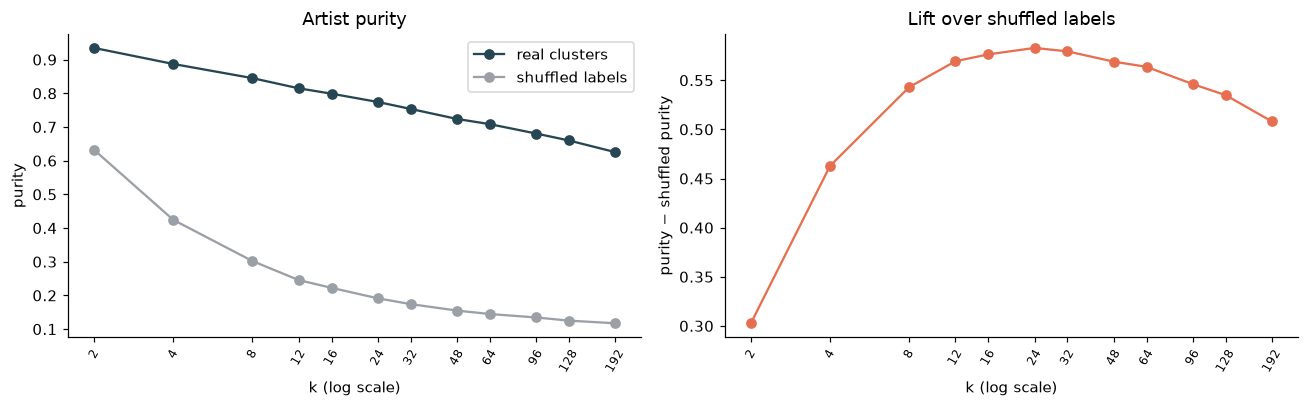

27,344 artists with >= 5 embedded tracks (689,236 tracks)
  k  purity  shuffled  lift  ratio
  2   0.935     0.632 0.303  1.479
  4   0.887     0.424 0.463  2.091
  8   0.845     0.302 0.543  2.797
 12   0.815     0.246 0.569  3.319
 16   0.799     0.223 0.576  3.590
 24   0.774     0.191 0.583  4.045
 32   0.754     0.174 0.579  4.326
 48   0.724     0.155 0.569  4.671
 64   0.708     0.145 0.564  4.893
 96   0.681     0.135 0.546  5.057
128   0.660     0.125 0.535  5.274
192   0.625     0.117 0.508  5.329


In [9]:
art = pd.read_parquet(DATA / "artist_item_mapping.parquet").drop_duplicates("item_id")
art_of_row = pd.Series(art.set_index("item_id")["artist_id"]).reindex(emb_ids).fillna(-1).astype(np.int64).to_numpy()
ok = art_of_row >= 0
sizes_a = pd.Series(art_of_row[ok]).value_counts(); big = set(sizes_a[sizes_a >= 5].index)
mask = ok & np.isin(art_of_row, list(big))
art_big = art_of_row[mask]

def purity(labels, art_ids):
    t = pd.DataFrame({"a": art_ids, "g": labels})
    return (t.groupby(["a", "g"]).size().groupby("a").max() / t.groupby("a").size()).mean()

def assign_all(C):
    out = np.empty(len(EN), dtype=np.int16)
    for s0 in range(0, len(EN), 200_000):
        out[s0:s0 + 200_000] = np.argmax(EN[s0:s0 + 200_000] @ C.T, axis=1)
    return out

rows = []
for k in K_GRID:
    lab_all = assign_all(store_real[(k, 0)][0])[mask]
    rows.append(dict(k=k, purity=purity(lab_all, art_big), shuffled=purity(rng.permutation(lab_all), art_big)))
pur = pd.DataFrame(rows); pur["lift"] = pur["purity"] - pur["shuffled"]; pur["ratio"] = pur["purity"] / pur["shuffled"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(pur["k"], pur["purity"], "o-", color=REAL, label="real clusters"); ax[0].plot(pur["k"], pur["shuffled"], "o-", color=NULL, label="shuffled labels")
ax[1].plot(pur["k"], pur["lift"], "o-", color=ACC)
for a_, t, yl in [(ax[0], "Artist purity", "purity"), (ax[1], "Lift over shuffled labels", "purity − shuffled purity")]:
    logk(a_); a_.set(title=t, xlabel="k (log scale)", ylabel=yl)
ax[0].legend(); plt.tight_layout(); plt.show()
print(f"{len(big):,} artists with >= 5 embedded tracks ({mask.sum():,} tracks)")
print(pur.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

### 6.1 Reading the artist purity

Tracks of the same artist land in the same cluster much more often than chance. At k = 32, 75% of an artist's tracks sit in the artist's most common cluster, against 17% with shuffled labels (4.3 times as much).

The **lift** (difference to shuffled) is largest at k = 16 to 32 (0.576, 0.583 and 0.579 at k = 16, 24, 32) and declines for larger k (0.51 at k = 192), while the *ratio* keeps growing (to 5.3) only because finer clusters make the shuffled baseline small.
The difference is the more meaningful number: beyond about k = 32, extra clusters split single artists across clusters faster than they separate different artists. This is the only criterion with a clear interior optimum, and
it lies at k of about 16 to 32.

Caveats: an artist is a rough proxy for sound (one artist can span styles); the analysis covers only artists with at least 5 embedded tracks (27,344 artists, 689k tracks); and we use the labels of seed 0 only.

## 7. Choice of k and anatomy of the chosen clustering

**Why.** No single criterion is decisive, so we put all of them side by side and decide on the combined evidence.
We then inspect the chosen clustering in detail, because a good score can hide a bad cluster (an empty one, a dominating one, an incoherent one).

**What we want to learn.** Which k is best supported, how strongly, and how comfortable we are with that choice.

      inertia  mean_cos  sil_exact  sil_simpl  min_share  max_share  stability_ari  purity  lift  sil_null  sil_gap
k                                                                                                                  
2   88476.562     0.410      0.090      0.252      0.455      0.545          0.544   0.935 0.303     0.015    0.075
4   78998.856     0.473      0.106      0.263      0.187      0.321          0.687   0.887 0.463     0.012    0.094
8   68470.489     0.544      0.133      0.295      0.086      0.161          0.685   0.845 0.543     0.010    0.123
12  62420.121     0.584      0.145      0.307      0.060      0.116          0.602   0.815 0.569     0.010    0.136
16  58087.630     0.613      0.159      0.323      0.038      0.087          0.640   0.799 0.576     0.009    0.150
24  51960.965     0.654      0.177      0.341      0.021      0.062          0.623   0.774 0.583     0.008    0.168
32  48007.897     0.680      0.185      0.348      0.012      0.045     

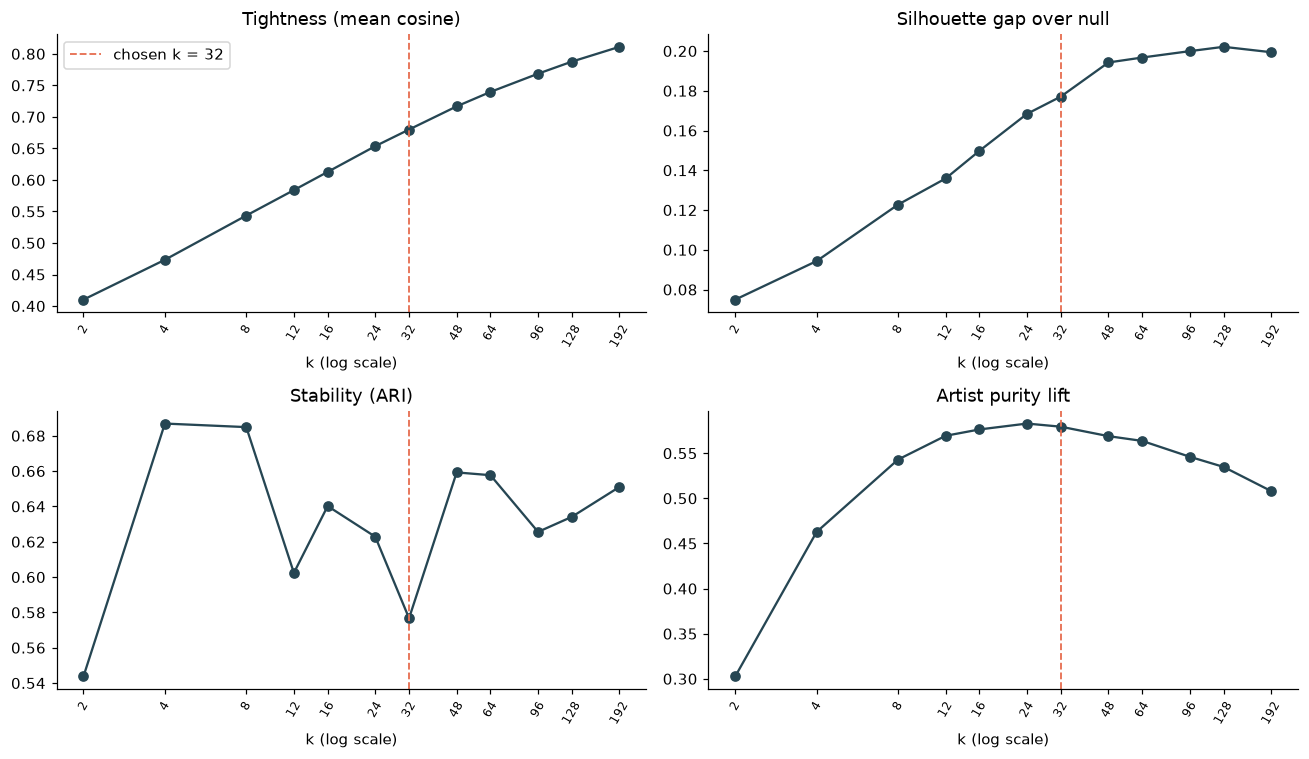

In [10]:
summ = (res_real.groupby("k").agg(inertia=("inertia", "mean"), mean_cos=("mean_cos", "mean"), sil_exact=("sil_exact", "mean"),
                                  sil_simpl=("sil_simpl", "mean"), min_share=("min_share", "mean"), max_share=("max_share", "mean"))
        .join(sg.mean().rename("stability_ari")).join(pur.set_index("k")[["purity", "lift"]])
        .join(gb[gb.data != "real"].set_index("k")["sil_exact"].rename("sil_null")))
summ["sil_gap"] = summ["sil_exact"] - summ["sil_null"]
print(summ.to_string(float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for a_, col, t in [(ax[0, 0], "mean_cos", "Tightness (mean cosine)"), (ax[0, 1], "sil_gap", "Silhouette gap over null"),
                   (ax[1, 0], "stability_ari", "Stability (ARI)"), (ax[1, 1], "lift", "Artist purity lift")]:
    a_.plot(summ.index, summ[col], "o-", color=REAL); a_.axvline(K_CHOSEN, color=ACC, ls="--", lw=1.2, label=f"chosen k = {K_CHOSEN}")
    logk(a_); a_.set(title=t, xlabel="k (log scale)")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

### 7.1 Decision

| Criterion | What it says |
|---|---|
| Elbow | no elbow; the saving per doubling is flat at about 18% from k = 32; the "knee" at 48 is an artefact of the grid |
| Silhouette | plateau of about 0.20 from k = 48, no meaningful maximum; weak in absolute terms (below 0.25) |
| Null model | real data beat noise at every k, with a gap that keeps growing: structure is real |
| Stability | ARI 0.58 to 0.69 at all k of at least 4; no k stands out; boundaries are partly arbitrary |
| Artist purity (lift) | **maximum at k of about 16 to 32**, declining afterwards |

**Decision: keep k = 32 (provisional, for discussion).** It sits at the top of the one criterion with an interior optimum (artist lift 0.579 vs maximum 0.583), its clusters are balanced
(all between about 1% and 4.5% of the tracks, none empty or tiny), its silhouette (0.185) is already 90% of the plateau value (0.205), and it was the initial working value of the project, so results computed with it stay comparable.

**It is not uniquely optimal.** The data do not single out one k; anything from about 16 to 64 is defensible, and earlier project analyses that used these pseudo-genres to compare recommended and organic listening kept the same direction of effect at k = 16, 32 and 64 (that check is not repeated here).
The main alternative is k = 48 (the detector's knee, start of the silhouette plateau, ARI 0.66), at a small cost in artist lift (0.569). The honest statement for the report is "k = 32 is a convenient point in a broad plateau", not "k = 32 is the true number of genres".

### 7.2 Anatomy of the chosen clustering
**Why.** To make sure the chosen k has no degenerate clusters and to see what kind of structure the clusters form.

**What we do and what each panel shows.**
- *Cluster sizes*: a clustering with a few huge clusters and many tiny ones would be a poor "genre" scheme.
- *Mean silhouette per cluster*: a cluster with a negative value would be a cluster whose members are on average closer to another cluster.
- *Centroid similarity matrix* (clusters ordered so that similar ones are adjacent): are the clusters isolated islands (dark everywhere except the diagonal) or neighbouring slices of one continuum (bright bands near the diagonal)?

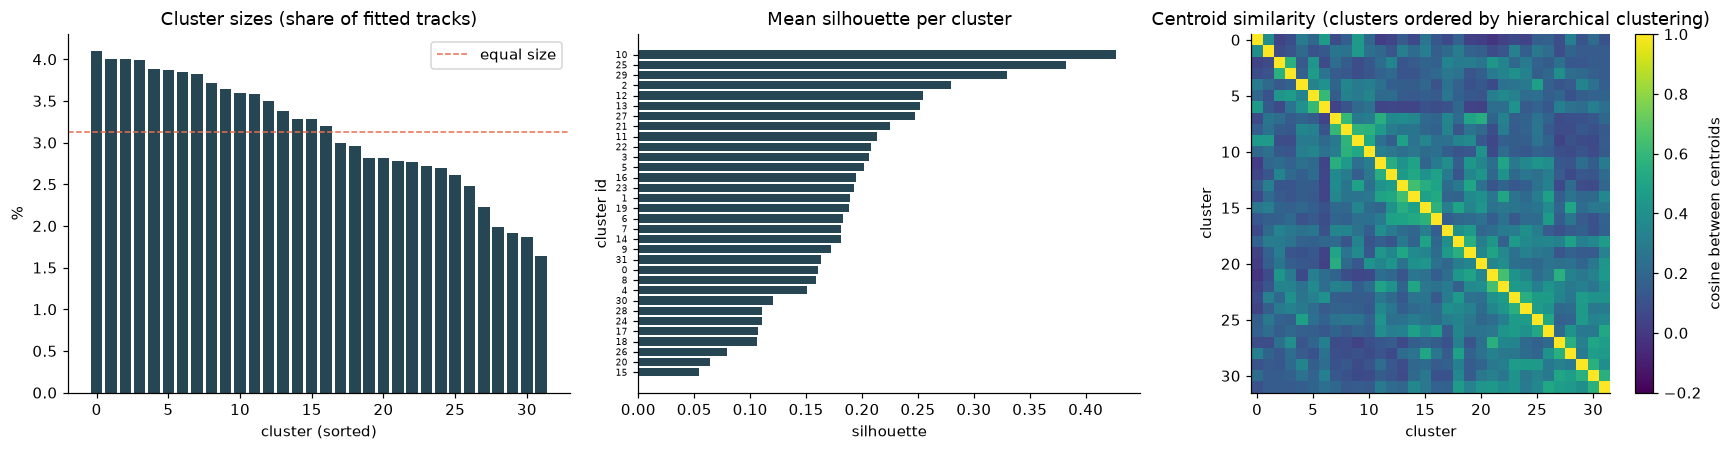

cluster sizes: min 1.64%, median 3.24%, max 4.10%; clusters with silhouette < 0: 0 of 32
cosine between centroids: mean 0.25; each cluster's nearest neighbour: median 0.56 (min 0.44, max 0.65)


In [11]:
C_k, lab_k = store_real[(K_CHOSEN, 0)]
sl = silhouette_samples(X[sil_idx], lab_k[sil_idx], metric="cosine")
cl_sil = pd.Series(sl).groupby(lab_k[sil_idx]).mean()
sz = np.bincount(lab_k, minlength=K_CHOSEN) / len(lab_k)
order = leaves_list(linkage(C_k, "average", metric="cosine"))
cc = C_k[order] @ C_k[order].T

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
o2 = np.argsort(-sz); ax[0].bar(range(K_CHOSEN), sz[o2] * 100, color=REAL)
ax[0].set(title="Cluster sizes (share of fitted tracks)", xlabel="cluster (sorted)", ylabel="%"); ax[0].axhline(100 / K_CHOSEN, color=ACC, ls="--", lw=1, label="equal size"); ax[0].legend()
o3 = np.argsort(cl_sil.values); ax[1].barh(range(K_CHOSEN), cl_sil.values[o3], color=np.where(cl_sil.values[o3] < 0, ACC, REAL))
ax[1].set_yticks(range(K_CHOSEN)); ax[1].set_yticklabels(cl_sil.index[o3], fontsize=6); ax[1].axvline(0, color="k", lw=1)
ax[1].set(title="Mean silhouette per cluster", xlabel="silhouette", ylabel="cluster id")
im = ax[2].imshow(cc, cmap="viridis", vmin=-.2, vmax=1); plt.colorbar(im, ax=ax[2], label="cosine between centroids")
ax[2].set(title="Centroid similarity (clusters ordered by hierarchical clustering)", xlabel="cluster", ylabel="cluster")
plt.tight_layout(); plt.show()
off = cc[~np.eye(K_CHOSEN, dtype=bool)]
nearest = np.sort(cc, axis=1)[:, -2]
print(f"cluster sizes: min {sz.min():.2%}, median {np.median(sz):.2%}, max {sz.max():.2%}; clusters with silhouette < 0: {(cl_sil < 0).sum()} of {K_CHOSEN}")
print(f"cosine between centroids: mean {off.mean():.2f}; each cluster's nearest neighbour: median {np.median(nearest):.2f} (min {nearest.min():.2f}, max {nearest.max():.2f})")

**Reading the anatomy.** At k = 32 the clusters range from 1.6% to 4.1% of the tracks (equal size would be 3.1%), and **no cluster has a negative mean silhouette**. A cluster's nearest neighbour has a centroid cosine of about 0.56
(range 0.44 to 0.65), while the average over all pairs of centroids is only 0.25: each pseudo-genre has a few close neighbours and many distant ones. This is a picture of *neighbourhoods on a continuum*,
not isolated islands, consistent with the weak silhouette and the moderate stability.

### 7.3 Validation against scikit-learn, and the hand-over file
**Why validate.** Our k-means is home-made, so we check it against the reference implementation (`sklearn.cluster.KMeans`) at the chosen k on identical data.
scikit-learn minimises Euclidean distance with un-normalised centroids, which is a slightly different objective, so we compare like with like: the cosine objective of its partition (with re-normalised centroids) and the ARI between the two partitions.
The ARI between implementations should be at least as high as the ARI between our own random starts (section 5); if it is, differences between implementations are smaller than differences between runs.

**Why export.** We write the pseudo-genre label of **every** embedded track to `RQ4_kmeans/`, together with the centroids, so that other analyses (for example the graph communities) can be compared with exactly these clusters, and so that results are reproducible without re-running this notebook.

In [12]:
sk = KMeans(K_CHOSEN, n_init=1, random_state=SEED).fit(X)
S_ = csr_matrix((np.ones(len(X), np.float32), (sk.labels_, np.arange(len(X)))), shape=(K_CHOSEN, len(X))) @ X
C_sk = S_ / np.linalg.norm(S_, axis=1, keepdims=True)
ours_cos = float((X * C_k[lab_k]).sum(1).mean()); sk_cos = float((X * np.asarray(C_sk)[sk.labels_]).sum(1).mean())
print(f"k={K_CHOSEN}: mean cosine to centroid ours {ours_cos:.4f} vs scikit-learn {sk_cos:.4f}; ARI(ours, scikit-learn) = {adjusted_rand_score(lab_k, sk.labels_):.2f}; "
      f"typical ARI between our own seeds = {sg.mean()[K_CHOSEN]:.2f}")

genre_all = assign_all(C_k)
OUT.mkdir(exist_ok=True)
pd.DataFrame({"item_id": emb_ids, "kmeans_cluster": genre_all}).to_csv(OUT / f"kmeans_pseudogenres_k{K_CHOSEN}.csv.gz", index=False)
np.savetxt(OUT / f"kmeans_centroids_k{K_CHOSEN}.csv.gz", C_k, delimiter=",", fmt="%.6f")
print(f"wrote RQ4_kmeans/kmeans_pseudogenres_k{K_CHOSEN}.csv.gz ({len(genre_all):,} tracks) and RQ4_kmeans/kmeans_centroids_k{K_CHOSEN}.csv.gz")

k=32: mean cosine to centroid ours 0.6809 vs scikit-learn 0.6826; ARI(ours, scikit-learn) = 0.71; typical ARI between our own seeds = 0.58


wrote RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz (847,921 tracks) and RQ4_kmeans/kmeans_centroids_k32.csv.gz


## 8. Summary and limitations

**Answer for the k-means side of RQ4.** The pseudo-genres are **not an artefact of k-means in the sense of fitting noise**: on every criterion that has a reference, the real embeddings beat shuffled data by a wide margin
(silhouette 0.19 vs 0.01 at k = 32), and the clusters line up with artist identity, a label k-means never saw (4.3 times the shuffled purity). But they are **graded rather than sharply separated**:
there is no elbow, the silhouette is weak (about 0.2), seeds agree only partly (ARI about 0.6), and neighbouring clusters are close. Pseudo-genres are best read as *regions of a continuous sound space*;
the number k = 32 is a convenience inside a broad plateau (about 16 to 64), not a discovered quantity.

**For the comparison with Louvain.** Use `RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz` (one cluster per embedded track, columns `item_id`, `kmeans_cluster`). Expect only moderate agreement: k-means agrees with itself at ARI of about 0.6, which is a practical ceiling.
A fairer reading of agreement is therefore relative to that self-agreement, and on cluster-level overlap rather than on single tracks.

**Limitations.**
- Clusters are fitted on a random 150k of the 848k tracks (all tracks are assigned afterwards); silhouette is exact only on 10k tracks (the centroid-based version covers 150k and agrees in shape).
- One embedding model and one k-means variant; other representations or algorithms (e.g. Gaussian mixtures, hierarchical clustering) could differ.
- The null model is lenient (see section 4), and artist purity is a rough external check (see section 6).
- Five seeds per k; stability is measured within the same sample, not across independent samples of tracks.
- This notebook does not re-check how downstream conclusions about listening behaviour change with k.
- All findings are associations in this dataset (Yambda-50M), not causal statements.